# 01 · Exploratory data analysis (Track A)
Dataset: `processed_data.mat` from the authors' repo (Krimsky & Ng, CS229 2018). Two subjects, ~180 rows each, 29 features, target = normalised metabolic rate.

In [1]:
import sys, warnings; sys.path.insert(0, '../src'); warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option('display.precision', 4)
from data import load_subject, load_all, summary, FEATURE_SETS, STEP_COLS, EMG_COLS, CTRL_COLS

## 1. Shape, cleaning and per-day means
S2 has one negative target (≈ −0.57). The authors' code drops it, and so do we, leaving 179 rows. That's why S2's variance here (0.036) is lower than the paper's constant-predictor MSE (0.0465), which included the bad row.

In [2]:
df = load_all()
print(df.groupby('subject').size())
summary().T

subject
S1    180
S2    179
dtype: int64


subject,S1,S2
rows,180.0000,179.0000
target_var,0.0657,0.0358
lag1_autocorr,0.8327,0.6250
day1_mean,1.1482,1.0634
day2_mean,1.0614,0.9642
day3_mean,0.6995,0.7396
day4_mean,0.6542,0.7504
day5_mean,0.6601,0.6800


## 2. Confirming the day structure (5 days × 36 rows)
If rows really are chronological in blocks of 36, the first control setting should repeat at each block start, and the target should step down between days.

In [3]:
for s in ['S1', 'S2']:
    d = load_subject(s, drop_invalid=False)
    print(s, 'ctrl1-4 at each day start:'); print(d.loc[d.row % 36 == 0, ['day'] + CTRL_COLS].to_string(index=False))

S1 ctrl1-4 at each day start:
 day  ctrl1  ctrl2  ctrl3  ctrl4
   1 36.448  52.91  26.16   9.76
   2 36.448  52.91  26.16   9.76
   3 36.448  52.91  26.16   9.76
   4 36.448  52.91  26.16   9.76
   5 36.448  52.91  26.16   9.76
S2 ctrl1-4 at each day start:
 day  ctrl1  ctrl2  ctrl3  ctrl4
   1 29.376  52.91  26.16   9.76
   2 29.376  52.91  26.16   9.76
   3 29.376  52.91  26.16   9.76
   4 29.376  52.91  26.16   9.76
   5 29.376  52.91  26.16   9.76


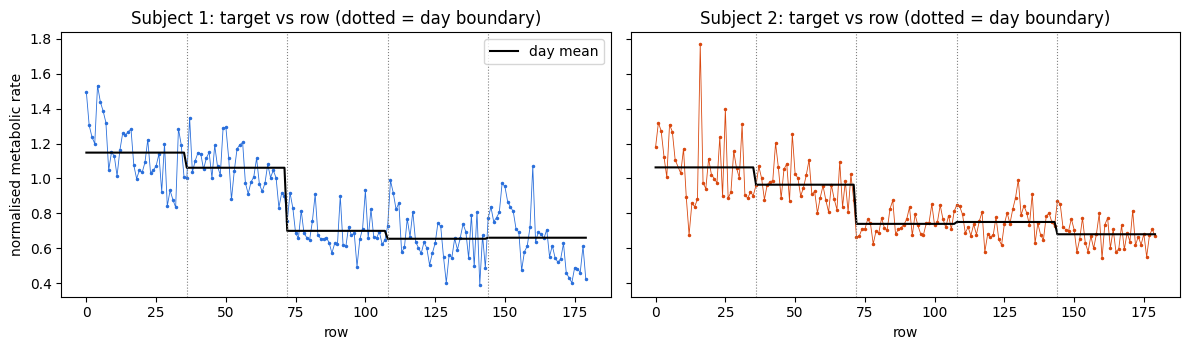

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for a, s, c in zip(ax, ['S1', 'S2'], ['#2a6fdb', '#d9480f']):
    d = load_subject(s)
    a.plot(d.row, d.metabolic, '.-', c=c, lw=.6, ms=3)
    a.plot(d.row, d.groupby('day').metabolic.transform('mean'), 'k-', lw=1.5, label='day mean')
    for k in range(1, 5): a.axvline(36 * k, c='grey', ls=':', lw=.8)
    a.set(title=f'Subject {s[-1]}: target vs row (dotted = day boundary)', xlabel='row')
ax[0].set_ylabel('normalised metabolic rate'); ax[0].legend(); plt.tight_layout()

The cost falls 35–45% from day 1 to day 5 as the subject learns to walk in the exo. The data is **non-stationary**, and neighbouring rows are strongly correlated (lag-1 autocorrelation 0.83 for S1). Both make random k-fold CV optimistic, which motivates leave-one-day-out.

## 3. Feature distributions and correlations

In [5]:
s1 = load_subject('S1')
s1[FEATURE_SETS['all']].describe().T[['mean', 'std', 'min', 'max']]

,mean,std,min,max
LFz_peak,1.0967,0.0592,0.9949,1.2903
L_peak_df,-0.0233,0.0635,-0.1771,0.1090
L_peak_pf,0.5746,0.2004,0.1791,0.9468
L_step_time,1.2166,0.0657,1.0900,1.3560
RFz_peak,0.8970,0.1297,0.4428,1.1494
R_peak_df,-0.0410,0.0735,-0.1948,0.1098
R_peak_pf,0.5621,0.1800,0.2545,0.9750
R_step_time,1.2167,0.0660,1.0910,1.3580
step_width,-2.2037,0.0484,-2.3272,-2.0873
emg1,0.2627,0.0274,0.1497,0.3112


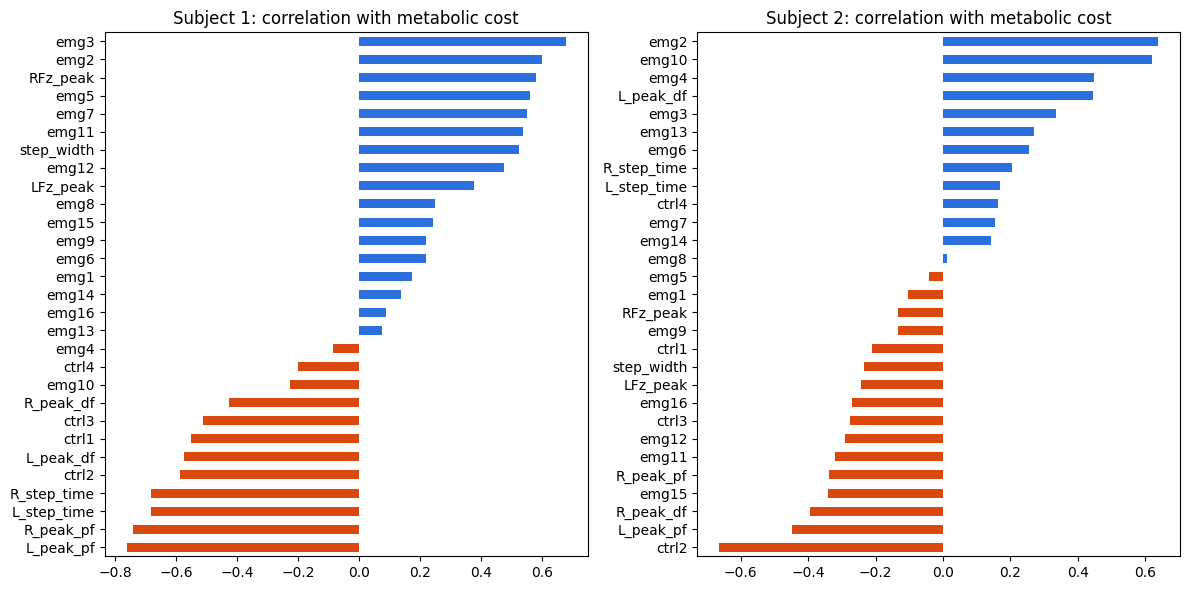

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 6))
for a, s in zip(ax, ['S1', 'S2']):
    d = load_subject(s)
    c = d[FEATURE_SETS['all'] + ['metabolic']].corr()['metabolic'].drop('metabolic').sort_values()
    c.plot.barh(ax=a, color=['#d9480f' if v < 0 else '#2a6fdb' for v in c])
    a.set_title(f'Subject {s[-1]}: correlation with metabolic cost')
plt.tight_layout()

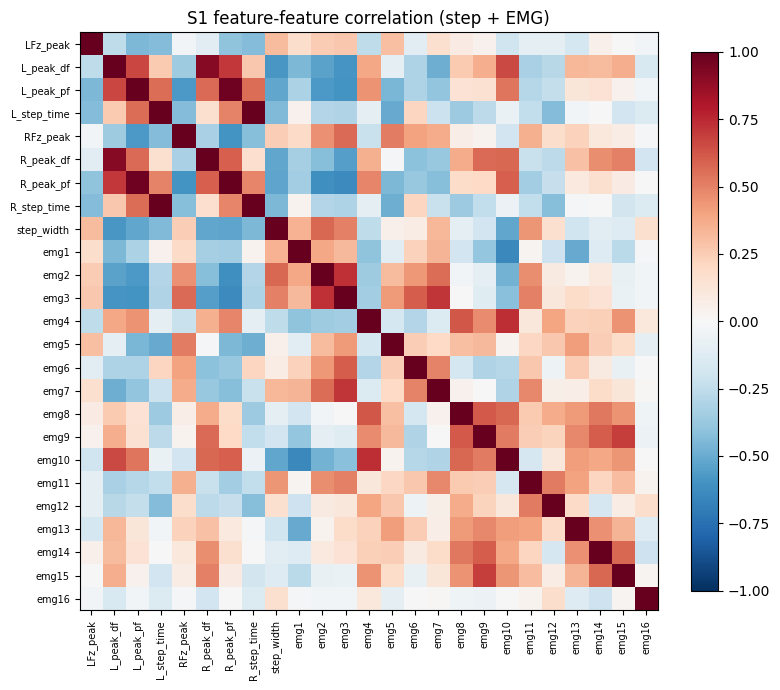

In [7]:
import matplotlib
d = load_subject('S1')[FEATURE_SETS['step+emg']]
fig, a = plt.subplots(figsize=(8, 7)); im = a.imshow(d.corr(), cmap='RdBu_r', vmin=-1, vmax=1)
a.set_xticks(range(25), d.columns, rotation=90, fontsize=7); a.set_yticks(range(25), d.columns, fontsize=7)
plt.colorbar(im, fraction=.04); a.set_title('S1 feature-feature correlation (step + EMG)'); plt.tight_layout()

## 4. Does the feature drift track the target drift?
Per-day means of a few features vs the target. If features shift with the day the same way the target does, a model can partly "read the day" from sensors.

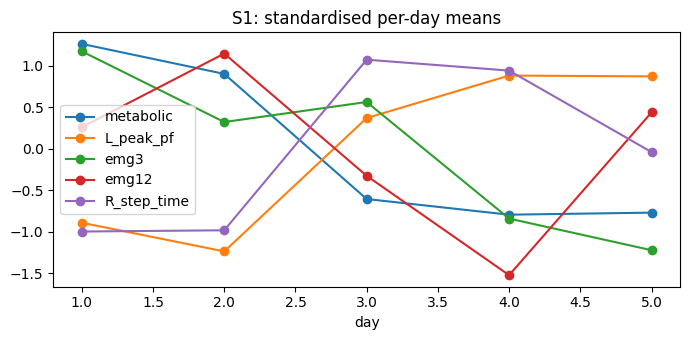

In [8]:
d = load_subject('S1')
m = d.groupby('day')[['metabolic', 'L_peak_pf', 'emg3', 'emg12', 'R_step_time']].mean()
((m - m.mean()) / m.std()).plot(marker='o', figsize=(7, 3.5), title='S1: standardised per-day means'); plt.tight_layout()

## Takeaways
- Data checks out: 180/179 rows, 5 × 36 chronological blocks, no NaNs.
- There's a strong downward learning trend across days, so LODO is the honest test.
- Step features, especially plantar-flexion, and several EMG channels correlate with cost. Control parameters correlate weakly.
- Many features are inter-correlated (L/R pairs, EMG groups), which motivates regularisation and feature selection.